# K-Means Clustering
**Name:** GUNTI RAHUL  |  **Roll No:** CH.SC.U4CSE24211  
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 10.6

## Exercise 1 - Old Faithful geyser eruptions
Segment eruptions by *duration* and *waiting time* to the next eruption.

(272, 3)
       duration  waiting
count    272.00   272.00
mean       3.49    70.90
std        1.14    13.59
min        1.60    43.00
25%        2.16    58.00
50%        4.00    76.00
75%        4.45    82.00
max        5.10    96.00


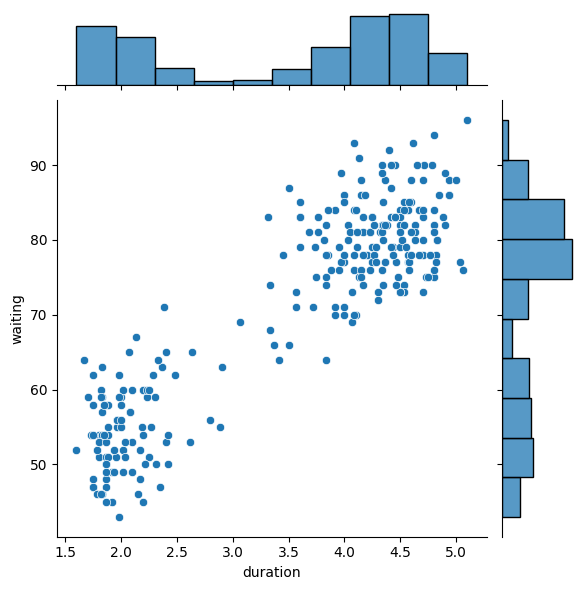

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

geyser = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/geyser.csv")
print(geyser.shape); print(geyser.describe().round(2))
sns.jointplot(data=geyser, x="duration", y="waiting", kind="scatter"); plt.show()

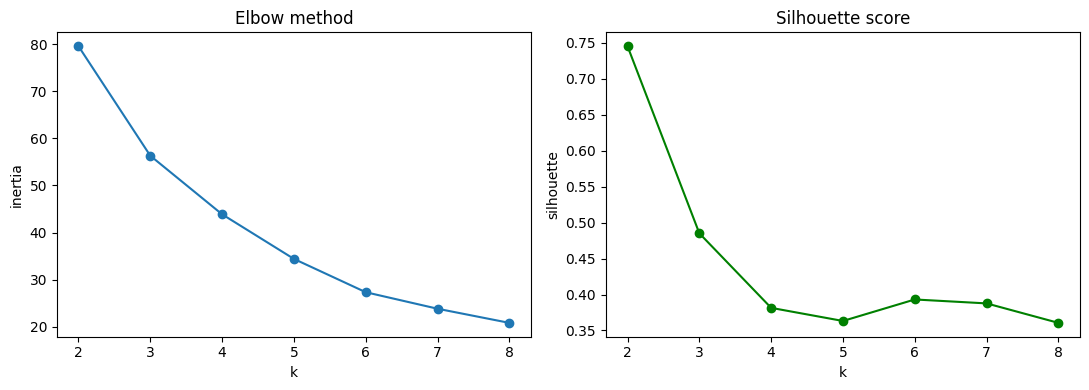

Best k by silhouette: 2


In [2]:
X = StandardScaler().fit_transform(geyser[["duration", "waiting"]])
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=262).fit(X); inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set(xlabel="k", ylabel="inertia", title="Elbow method")
ax[1].plot(ks, sil, "o-", c="g"); ax[1].set(xlabel="k", ylabel="silhouette", title="Silhouette score")
plt.tight_layout(); plt.show()
print("Best k by silhouette:", list(ks)[int(np.argmax(sil))])

   duration  waiting
0      4.30    80.08
1      2.05    54.59
         count  mean_duration  mean_waiting
cluster                                    
0          174           4.30         80.08
1           98           2.05         54.59


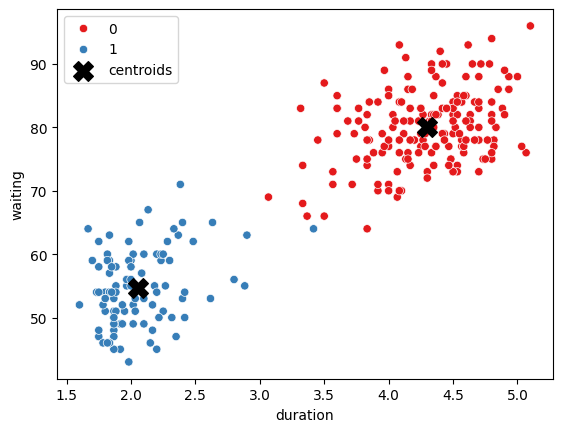

In [3]:
km = KMeans(2, n_init=10, random_state=262).fit(X)
geyser["cluster"] = km.labels_
centers = StandardScaler().fit(geyser[["duration", "waiting"]]).inverse_transform(km.cluster_centers_)
print(pd.DataFrame(centers, columns=["duration", "waiting"]).round(2))
print(geyser.groupby("cluster").agg(count=("duration", "size"), mean_duration=("duration", "mean"), mean_waiting=("waiting", "mean")).round(2))
sns.scatterplot(data=geyser, x="duration", y="waiting", hue="cluster", palette="Set1")
plt.scatter(centers[:, 0], centers[:, 1], c="k", s=200, marker="X", label="centroids"); plt.legend(); plt.show()

**Reading the result:** the data forms two regimes - *short* eruptions followed by short waits, and *long* eruptions followed by long waits - so a park ranger can estimate the wait from the eruption length.

## Exercise 2 - Image compression with K-Means (396 x 396 x 3)
Each pixel is an RGB point. Clustering all pixels into *k* colours and replacing each pixel by its centroid stores the image with only *k* distinct colours. A 396x396x3 test image is generated so no file is needed (swap in any photo resized to 396x396).

shape: (396, 396, 3)


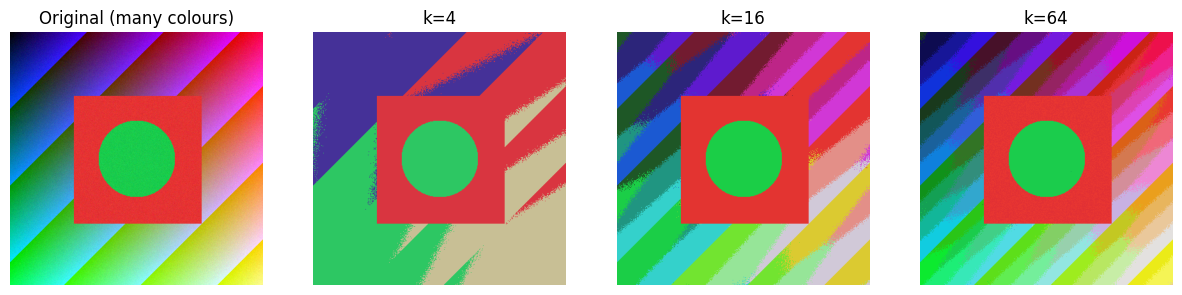

,k colours,MSE,PSNR (dB)
0,4,0.03269,14.9
1,16,0.00902,20.4
2,64,0.00291,25.4


In [4]:
yy, xx = np.mgrid[0:396, 0:396]
img = np.stack([xx / 396, yy / 396, ((xx + yy) % 120) / 120], -1)
img[100:300, 100:300] = [.9, .2, .2]; img[(xx - 198) ** 2 + (yy - 198) ** 2 < 60 ** 2] = [.1, .8, .3]
img = np.clip(img + np.random.default_rng(262).normal(0, .02, img.shape), 0, 1)
print("shape:", img.shape)
pixels = img.reshape(-1, 3)
fig, ax = plt.subplots(1, 4, figsize=(15, 4)); ax[0].imshow(img); ax[0].set_title("Original (many colours)")
stats = []
for a, k in zip(ax[1:], [4, 16, 64]):
    km = KMeans(k, n_init=3, random_state=262).fit(pixels[::7])
    out = km.cluster_centers_[km.predict(pixels)].reshape(img.shape)
    mse = ((img - out) ** 2).mean(); stats.append((k, round(mse, 5), round(10 * np.log10(1 / mse), 1)))
    a.imshow(out); a.set_title(f"k={k}")
for a in ax: a.axis("off")
plt.show()
pd.DataFrame(stats, columns=["k colours", "MSE", "PSNR (dB)"])

In [5]:
orig_bits = 396 * 396 * 24
rows = [(k, round(orig_bits / (396 * 396 * np.ceil(np.log2(k)) + k * 24), 1)) for k in (4, 16, 64)]
pd.DataFrame(rows, columns=["k", "approx. compression ratio (x)"])

,k,approx. compression ratio (x)
0,4,12.0
1,16,6.0
2,64,4.0


### Conclusion
Elbow and silhouette both support two geyser clusters. For images, k trades quality (PSNR) against size: k=4 compresses ~12x but is posterised, while k=64 is near-original at ~4x.